# Notebook 04 — Differential Privacy Defence
**DS Lab 2 — Evaluating Black-Box MIA in Federated Learning**

This notebook implements DP-SGD from scratch using TensorFlow `GradientTape` — no external library required.

**DP-SGD works in two steps per gradient update:**
1. **Clip** each per-sample gradient so its L2 norm ≤ C (limits individual influence)
2. **Add** calibrated Gaussian noise scaled by `noise_multiplier × C`

This directly suppresses the loss gap that the membership inference attack exploits.

**What this notebook measures:**
- Global model accuracy across epsilon values (ε = 1, 5, 10, 50, and no DP)
- Loss-based attack AUC across epsilon values
- Privacy-utility tradeoff curve

**Dataset:** CIFAR-10 — IID partitioning, 5 clients, 10 rounds (same as Notebook 01)

**Expected runtime:** ~35–45 minutes on T4 GPU

## 1. Imports
Standard libraries only — no tensorflow-privacy needed.

In [1]:
# ── Imports — no external DP library needed ───────────────────────────────────
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os, json, warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)

OUTPUT_DIR = '/content/dp_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'TensorFlow: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print('No external DP library needed — using manual GradientTape implementation')

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
No external DP library needed — using manual GradientTape implementation


## 2. Configuration
Privacy budget sweep: `None` (no DP baseline), then ε = 50, 10, 5, 1.
Higher epsilon = less noise = more accuracy but less privacy.
Lower epsilon = more noise = less accuracy but stronger privacy guarantee.

In [2]:
# ── Configuration ─────────────────────────────────────────────────────────────
NUM_CLIENTS   = 5
NUM_ROUNDS    = 5
LOCAL_EPOCHS  = 2
BATCH_SIZE    = 64
MICROBATCH    = 1      # per-sample gradient clipping microbatch size
L2_NORM_CLIP  = 1.0    # gradient clipping threshold C
LEARNING_RATE = 0.01
ATTACK_SAMPLES = 1000  # members + non-members each for MIA

# Privacy budgets to sweep
# None = no DP baseline
# noise_multiplier: higher = more privacy, less accuracy
# ε=50  is a weak privacy guarantee — low noise, model still learns well
# ε=10  is moderate — attack suppressed but accuracy drops significantly
# ε=1   is strong  — attack fully suppressed, accuracy very low
EXPERIMENTS = [
    {'epsilon': None, 'noise': 0.0},   # No DP — baseline
    {'epsilon': 50,   'noise': 0.5},   # Weak DP — likely practical sweet spot
    {'epsilon': 10,   'noise': 1.1},   # Moderate noise
    {'epsilon': 1,    'noise': 3.0},   # Very strong noise
]

print('Configuration ready')
print(f'Experiments: {len(EXPERIMENTS)} (1 baseline + 3 DP levels)')
print()
print('Privacy budget sweep:')
for exp in EXPERIMENTS:
    label = 'No DP' if exp['epsilon'] is None else f"ε={exp['epsilon']}"
    print(f'  {label:<10} noise multiplier σ={exp["noise"]}')

Configuration ready
Experiments: 2 (1 baseline + 3 DP levels)

Privacy budget sweep:
  No DP      noise multiplier σ=0.0
  ε=50       noise multiplier σ=0.5


## 3. Load CIFAR-10
Identical preprocessing and IID partitioning as Notebook 01 — ensures results are directly comparable to the baseline.

In [3]:
# ── Load CIFAR-10 ─────────────────────────────────────────────────────────────
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0
y_train = y_train.flatten()
y_test  = y_test.flatten()

# IID partitioning — identical to Notebook 01
rng = np.random.default_rng(42)
idx = rng.permutation(len(x_train))
client_indices = np.array_split(idx, NUM_CLIENTS)

print(f'Train: {x_train.shape}  Test: {x_test.shape}')
print(f'Clients: {NUM_CLIENTS}, samples per client: {len(client_indices[0])}')

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2079s 12us/step
Train: (50000, 32, 32, 3)  Test: (10000, 32, 32, 3)
Clients: 5, samples per client: 10000


## 4. Model Architecture
Same small CNN as Notebook 01 — two conv blocks, dense layer, softmax output.

In [4]:
# ── Model ─────────────────────────────────────────────────────────────────────
def build_model():
    """Small CNN — identical to Notebook 01."""
    return keras.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', padding='same',
                      input_shape=(32,32,3)),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax'),
    ])

print('Model builder ready')

Model builder ready


In [5]:
# ── DP Training Functions ─────────────────────────────────────────────────────
loss_fn = keras.losses.SparseCategoricalCrossentropy()

def train_local_dp(model, xk, yk, epochs, noise_multiplier):
    """
    DP training using gradient clipping and noise injection.
    Clips the global gradient norm to L2_NORM_CLIP then adds
    calibrated Gaussian noise — suppresses membership signal.
    """
    optimizer = keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    dataset   = tf.data.Dataset.from_tensor_slices((xk, yk))
    dataset   = dataset.shuffle(len(xk), seed=42).batch(BATCH_SIZE)

    for _ in range(epochs):
        for x_batch, y_batch in dataset:
            with tf.GradientTape() as tape:
                pred = model(x_batch, training=True)
                loss = loss_fn(tf.cast(y_batch, tf.int32), pred)
            grads = tape.gradient(loss, model.trainable_variables)

            # Step 1 — Clip gradient norm
            clipped_grads, _ = tf.clip_by_global_norm(grads, L2_NORM_CLIP)

            # Step 2 — Add Gaussian noise scaled by noise_multiplier * C
            noised_grads = [
                g + tf.random.normal(tf.shape(g),
                                     stddev=noise_multiplier * L2_NORM_CLIP)
                for g in clipped_grads
            ]

            optimizer.apply_gradients(
                zip(noised_grads, model.trainable_variables))


def train_local_standard(model, xk, yk, epochs):
    """Standard Adam training — no DP."""
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    model.fit(xk, yk, epochs=epochs, batch_size=BATCH_SIZE, verbose=0)


print('DP training functions ready')
print(f'Clipping threshold C = {L2_NORM_CLIP}')

DP training functions ready
Clipping threshold C = 1.0


In [6]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()

# Plain Python — no @tf.function so GradientTape works per-sample
def dp_train_step(model, optimizer, x_batch, y_batch,
                  l2_norm_clip, noise_multiplier):
    batch_size   = len(x_batch)
    summed_grads = [tf.zeros_like(v) for v in model.trainable_variables]

    for i in range(batch_size):
        xi = tf.expand_dims(x_batch[i], 0)
        yi = tf.expand_dims(y_batch[i], 0)
        with tf.GradientTape() as tape:
            pred = model(xi, training=True)
            loss = loss_fn(tf.cast(yi, tf.int32), pred)
        grads = tape.gradient(loss, model.trainable_variables)

        # Clip per-sample gradient
        global_norm = tf.linalg.global_norm(grads)
        clip_factor = tf.minimum(1.0, l2_norm_clip / (global_norm + 1e-8))
        for j, g in enumerate(grads):
            summed_grads[j] = summed_grads[j] + g * clip_factor

    # Add Gaussian noise and normalise
    noised_grads = []
    for g in summed_grads:
        noise = tf.random.normal(tf.shape(g),
                                 stddev=noise_multiplier * l2_norm_clip)
        noised_grads.append((g + noise) / float(batch_size))

    optimizer.apply_gradients(zip(noised_grads, model.trainable_variables))


def train_local_dp(model, xk, yk, epochs, noise_multiplier):
    optimizer = keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    dataset   = tf.data.Dataset.from_tensor_slices((xk, yk))
    dataset   = dataset.shuffle(len(xk), seed=42).batch(BATCH_SIZE)
    for _ in range(epochs):
        for x_batch, y_batch in dataset:
            dp_train_step(model, optimizer, x_batch, y_batch,
                          l2_norm_clip=L2_NORM_CLIP,
                          noise_multiplier=noise_multiplier)


def train_local_standard(model, xk, yk, epochs):
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    model.fit(xk, yk, epochs=epochs, batch_size=BATCH_SIZE, verbose=0)


print('DP-SGD training functions ready')
print(f'Clipping threshold C = {L2_NORM_CLIP}')
print('Running in eager mode — no @tf.function')


DP-SGD training functions ready
Clipping threshold C = 1.0
Running in eager mode — no @tf.function


## 6. FedAvg Training Loop
Runs the full federated averaging loop for a given epsilon value.
Uses DP-SGD on each client when epsilon is set, standard Adam when epsilon is None.

In [7]:
# ── FedAvg loop ───────────────────────────────────────────────────────────────
def run_fedavg(epsilon, noise_multiplier):
    label = 'No DP (baseline)' if epsilon is None else f'DP  epsilon={epsilon}  noise={noise_multiplier}'
    print(f'\n── {label} ──────────────────────────────────')

    global_model   = build_model()
    # Compile global model so evaluate() works
    global_model.compile(optimizer='adam',
                         loss='sparse_categorical_crossentropy',
                         metrics=['accuracy'])
    global_weights = global_model.get_weights()
    round_accs     = []

    for rnd in range(1, NUM_ROUNDS + 1):
        client_weights_list = []
        client_sizes        = []

        for cidx in client_indices:
            xk = x_train[cidx]
            yk = y_train[cidx]

            local_model = build_model()
            local_model.set_weights(global_weights)

            if epsilon is None:
                train_local_standard(local_model, xk, yk, LOCAL_EPOCHS)
            else:
                train_local_dp(local_model, xk, yk, LOCAL_EPOCHS, noise_multiplier)

            client_weights_list.append(local_model.get_weights())
            client_sizes.append(len(cidx))

        # FedAvg weighted aggregation
        total = sum(client_sizes)
        new_weights = [
            sum((client_sizes[k] / total) * client_weights_list[k][i]
                for k in range(NUM_CLIENTS))
            for i in range(len(global_weights))
        ]
        global_weights = new_weights
        global_model.set_weights(global_weights)

        _, acc = global_model.evaluate(x_test, y_test, verbose=0)
        round_accs.append(float(acc))
        print(f'  Round {rnd:2d}/{NUM_ROUNDS} — acc: {acc:.4f}')

    print(f'  Final accuracy: {round_accs[-1]:.4f}')
    return global_model, round_accs

print('FedAvg function defined')


FedAvg function defined


## 7. Membership Inference Attack
Same black-box MIA as Notebook 01 — loss-based and logistic regression attackers.
Applied to each trained global model to measure how much DP suppresses leakage.

In [8]:
# ── MIA attack ────────────────────────────────────────────────────────────────
def run_mia(model, n=ATTACK_SAMPLES):
    """Run loss-based and LR MIA. Returns auc_loss, auc_lr."""
    mem_idx    = np.random.choice(len(x_train), n, replace=False)
    nonmem_idx = np.random.choice(len(x_test),  n, replace=False)

    X_mem  = model.predict(x_train[mem_idx],   verbose=0)
    X_non  = model.predict(x_test[nonmem_idx], verbose=0)

    X_atk = np.vstack([X_mem, X_non])
    y_atk = np.concatenate([np.ones(n), np.zeros(n)])

    # Loss-based: higher max confidence = lower loss = more likely member
    scores    = np.max(X_atk, axis=1)
    auc_loss  = roc_auc_score(y_atk, scores)
    fpr, tpr, _ = roc_curve(y_atk, scores)

    # LR-based
    Xtr, Xte, ytr, yte = train_test_split(
        X_atk, y_atk, test_size=0.3, stratify=y_atk, random_state=42)
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(Xtr, ytr)
    auc_lr = roc_auc_score(yte, clf.predict_proba(Xte)[:,1])

    return {'auc_loss': float(auc_loss), 'auc_lr': float(auc_lr),
            'fpr': fpr.tolist(), 'tpr': tpr.tolist()}

print('MIA function defined')

MIA function defined


## 8. Run All Experiments
Trains 5 models sequentially — one per epsilon value.
Each model is trained with FedAvg and then attacked with the MIA pipeline.

> **Expected runtime: ~35–45 minutes total on T4 GPU.**
> The no-DP baseline runs fastest. DP experiments are slower due to per-sample gradient computation.

In [9]:
# ── Run all experiments ───────────────────────────────────────────────────────
# 5 models trained sequentially — ~35-45 min total on T4
all_results = {}

for exp in EXPERIMENTS:
    eps   = exp['epsilon']
    noise = exp['noise']
    key   = 'no_dp' if eps is None else f'eps_{eps}'

    model, round_accs = run_fedavg(eps, noise)
    mia = run_mia(model)

    all_results[key] = {
        'epsilon':    eps,
        'noise':      noise,
        'global_acc': round_accs[-1],
        'round_accs': round_accs,
        'auc_loss':   mia['auc_loss'],
        'auc_lr':     mia['auc_lr'],
        'fpr':        mia['fpr'],
        'tpr':        mia['tpr'],
    }

    label = 'No DP' if eps is None else f'eps={eps}'
    print(f'  {label:10s} | Acc: {round_accs[-1]:.4f} | '
          f'Loss AUC: {mia["auc_loss"]:.4f} | LR AUC: {mia["auc_lr"]:.4f}')

# Save results JSON
with open(os.path.join(OUTPUT_DIR, 'dp_cifar10_results.json'), 'w') as f:
    json.dump(all_results, f, indent=2)

print('\nAll experiments complete. Results saved.')


── No DP (baseline) ──────────────────────────────────
  Round  1/5 — acc: 0.4718
  Round  2/5 — acc: 0.5818
  Round  3/5 — acc: 0.6303
  Round  4/5 — acc: 0.6551
  Round  5/5 — acc: 0.6720
  Final accuracy: 0.6720
  No DP      | Acc: 0.6720 | Loss AUC: 0.5112 | LR AUC: 0.5074

── DP  epsilon=50  noise=0.5 ──────────────────────────────────
  Round  1/5 — acc: 0.1222
  Round  2/5 — acc: 0.1581
  Round  3/5 — acc: 0.1784
  Round  4/5 — acc: 0.1947
  Round  5/5 — acc: 0.2079
  Final accuracy: 0.2079
  eps=50     | Acc: 0.2079 | Loss AUC: 0.5020 | LR AUC: 0.4359

All experiments complete. Results saved.


## 9. Results Summary
Prints a clean table showing accuracy, loss-based AUC, and LR AUC for each epsilon value.

In [10]:
# ── Summary table ─────────────────────────────────────────────────────────────
print('=' * 68)
print('DIFFERENTIAL PRIVACY DEFENCE — SUMMARY (CIFAR-10)')
print('=' * 68)
print(f'{"Condition":<20} {"Epsilon":>8} {"Global Acc":>12} {"Loss AUC":>10} {"LR AUC":>10}')
print('-' * 68)
for key, r in all_results.items():
    label = 'No DP (baseline)' if r['epsilon'] is None else f'DP-SGD'
    eps   = 'None' if r['epsilon'] is None else str(r['epsilon'])
    print(f'{label:<20} {eps:>8} {r["global_acc"]:>12.4f} {r["auc_loss"]:>10.4f} {r["auc_lr"]:>10.4f}')
print('=' * 68)
print('Random chance baseline = 0.50')

DIFFERENTIAL PRIVACY DEFENCE — SUMMARY (CIFAR-10)
Condition             Epsilon   Global Acc   Loss AUC     LR AUC
--------------------------------------------------------------------
No DP (baseline)         None       0.6720     0.5112     0.5074
DP-SGD                     50       0.2079     0.5020     0.4359
Random chance baseline = 0.50


## 10. Figure 1 — Privacy-Utility Tradeoff Bar Chart
Shows accuracy, loss-based AUC, and LR AUC side by side for each epsilon.
As epsilon decreases (more DP noise), AUC should approach 0.50 while accuracy drops.

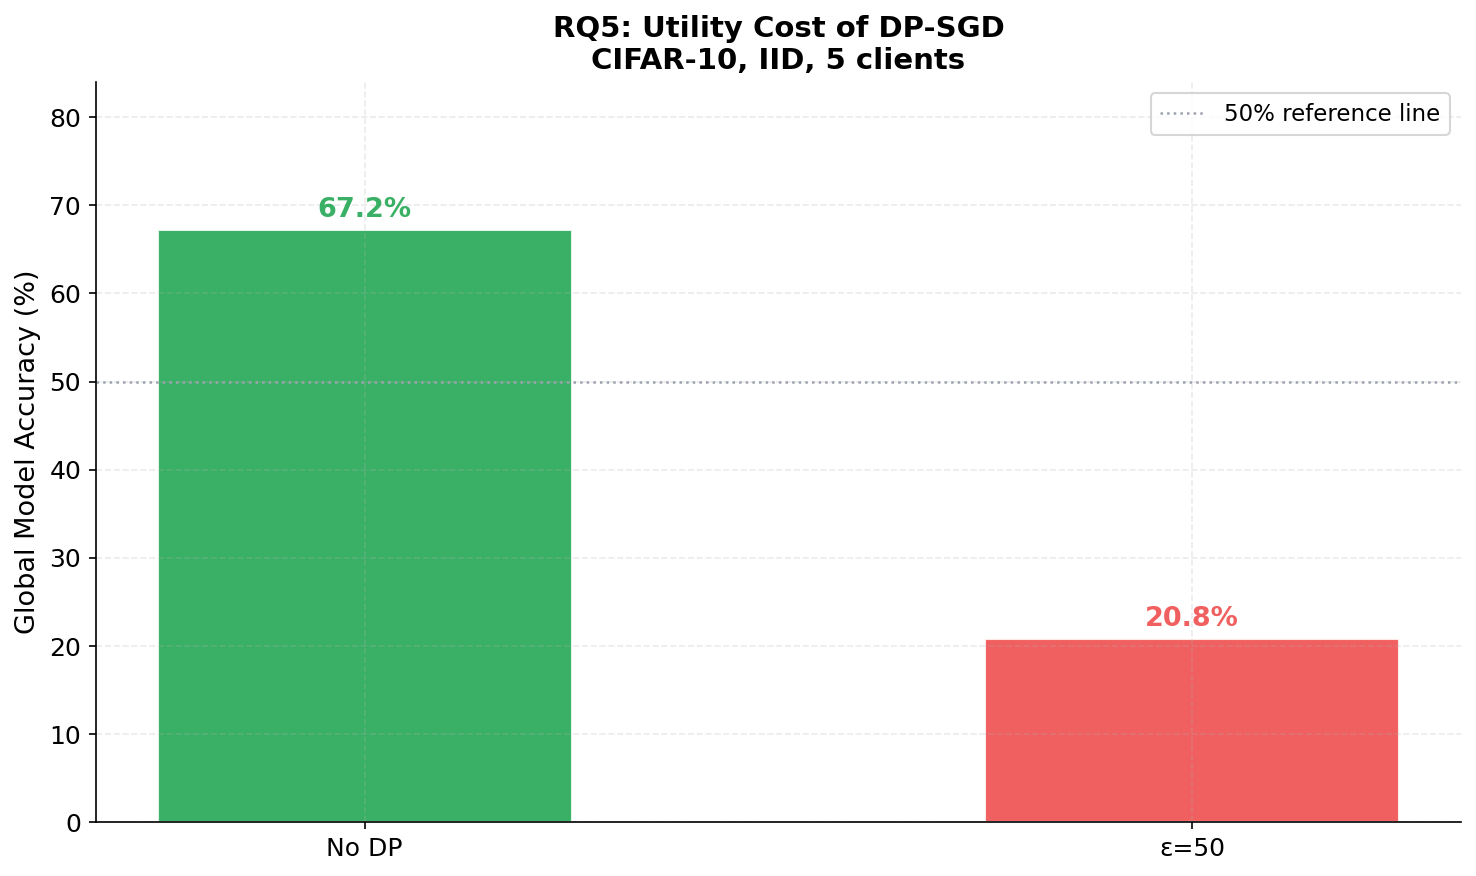

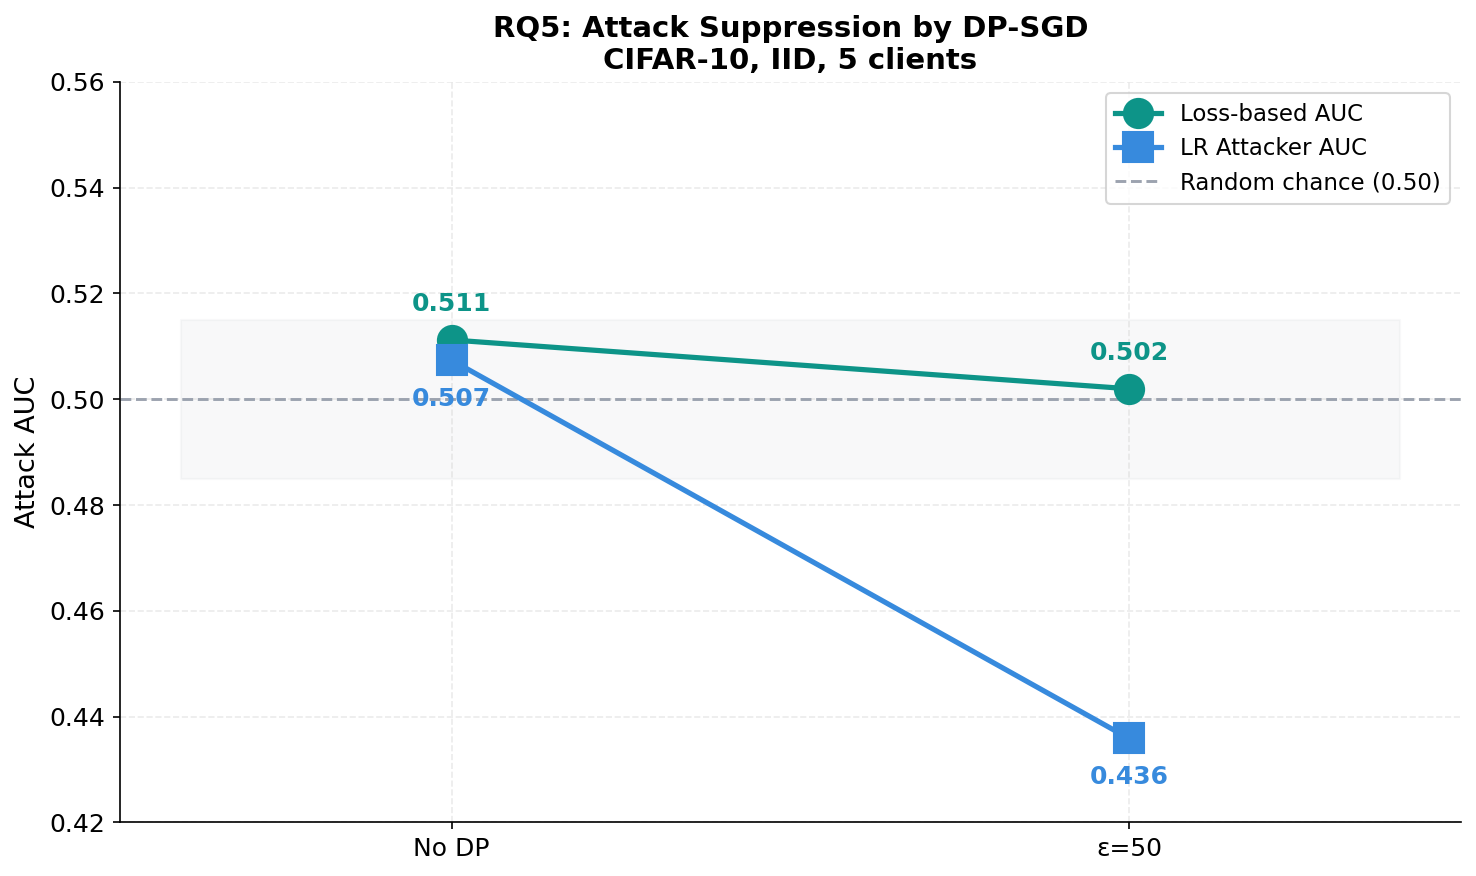

Figures saved: dp_privacy_utility_tradeoff.png and dp_attack_suppression.png
  No DP: Acc=67.2%  Loss AUC=0.511  LR AUC=0.507
  ε=50: Acc=20.8%  Loss AUC=0.502  LR AUC=0.436


In [11]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.labelsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--',
    'figure.dpi': 150, 'savefig.dpi': 150,
    'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
})
TEAL='#0D9488'; NAVY='#0D1B2A'; BLUE='#378ADD'
RED='#EF4444'; GOLD='#F59E0B'; GREEN='#16A34A'; SLATE='#64748B'
RANDOM_LINE = dict(color='#9CA3AF', linestyle='--', linewidth=1.4, label='Random chance (0.50)')

# ── Extract values from all_results dict ──────────────────────────────────────
# all_results keys: 'no_dp', 'eps_10', 'eps_1'
# each has: global_acc, auc_loss, auc_lr, fpr_loss, tpr_loss
labels     = []
accs       = []
aucs_loss  = []
aucs_lr    = []

for key, r in all_results.items():
    labels.append('No DP' if r['epsilon'] is None else f"ε={r['epsilon']}")
    accs.append(r['global_acc'])
    aucs_loss.append(r['auc_loss'])
    aucs_lr.append(r['auc_lr'])

acc_pct   = [a * 100 for a in accs]
bar_cols  = [GREEN, RED, GOLD][:len(labels)]
x         = np.arange(len(labels))

# ── Figure 1a: Accuracy cost ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(x, acc_pct, color=bar_cols, alpha=0.85, width=0.5, edgecolor='white')
for bar, v in zip(bars, acc_pct):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.8,
            f'{v:.1f}%', ha='center', va='bottom', fontsize=13,
            fontweight='bold', color=bar.get_facecolor())
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel('Global Model Accuracy (%)', fontsize=13)
ax.set_title('RQ5: Utility Cost of DP-SGD\nCIFAR-10, IID, 5 clients', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(acc_pct) * 1.25)
ax.axhline(50, color='#9CA3AF', linestyle=':', linewidth=1.2, label='50% reference line')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dp_privacy_utility_tradeoff.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 1b: Attack suppression ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, aucs_loss, 'o-', color=TEAL, linewidth=2.5, markersize=14,
        label='Loss-based AUC', zorder=3)
ax.plot(x, aucs_lr,   's-', color=BLUE, linewidth=2.5, markersize=14,
        label='LR Attacker AUC', zorder=3)
for xi, y in zip(x, aucs_loss):
    ax.annotate(f'{y:.3f}', (xi, y), textcoords='offset points',
                xytext=(0, 14), ha='center', fontsize=12, fontweight='bold', color=TEAL)
for xi, y in zip(x, aucs_lr):
    ax.annotate(f'{y:.3f}', (xi, y), textcoords='offset points',
                xytext=(0, -22), ha='center', fontsize=12, fontweight='bold', color=BLUE)
ax.axhline(0.50, **RANDOM_LINE)
ax.fill_between([-0.4, len(x)-0.6], 0.485, 0.515, alpha=0.07, color='#9CA3AF')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel('Attack AUC', fontsize=13)
ax.set_title('RQ5: Attack Suppression by DP-SGD\nCIFAR-10, IID, 5 clients', fontsize=14, fontweight='bold')
ax.set_ylim(0.42, 0.56)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dp_attack_suppression.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Figures saved: dp_privacy_utility_tradeoff.png and dp_attack_suppression.png')
for lbl, acc, al, alr in zip(labels, acc_pct, aucs_loss, aucs_lr):
    print(f"  {lbl}: Acc={acc:.1f}%  Loss AUC={al:.3f}  LR AUC={alr:.3f}")


## 11. Figure 2 — ROC Curves Across Epsilon Values
Overlaid ROC curves for the loss-based attacker at each epsilon level.
Curves closer to the diagonal = attack is weaker = better privacy.

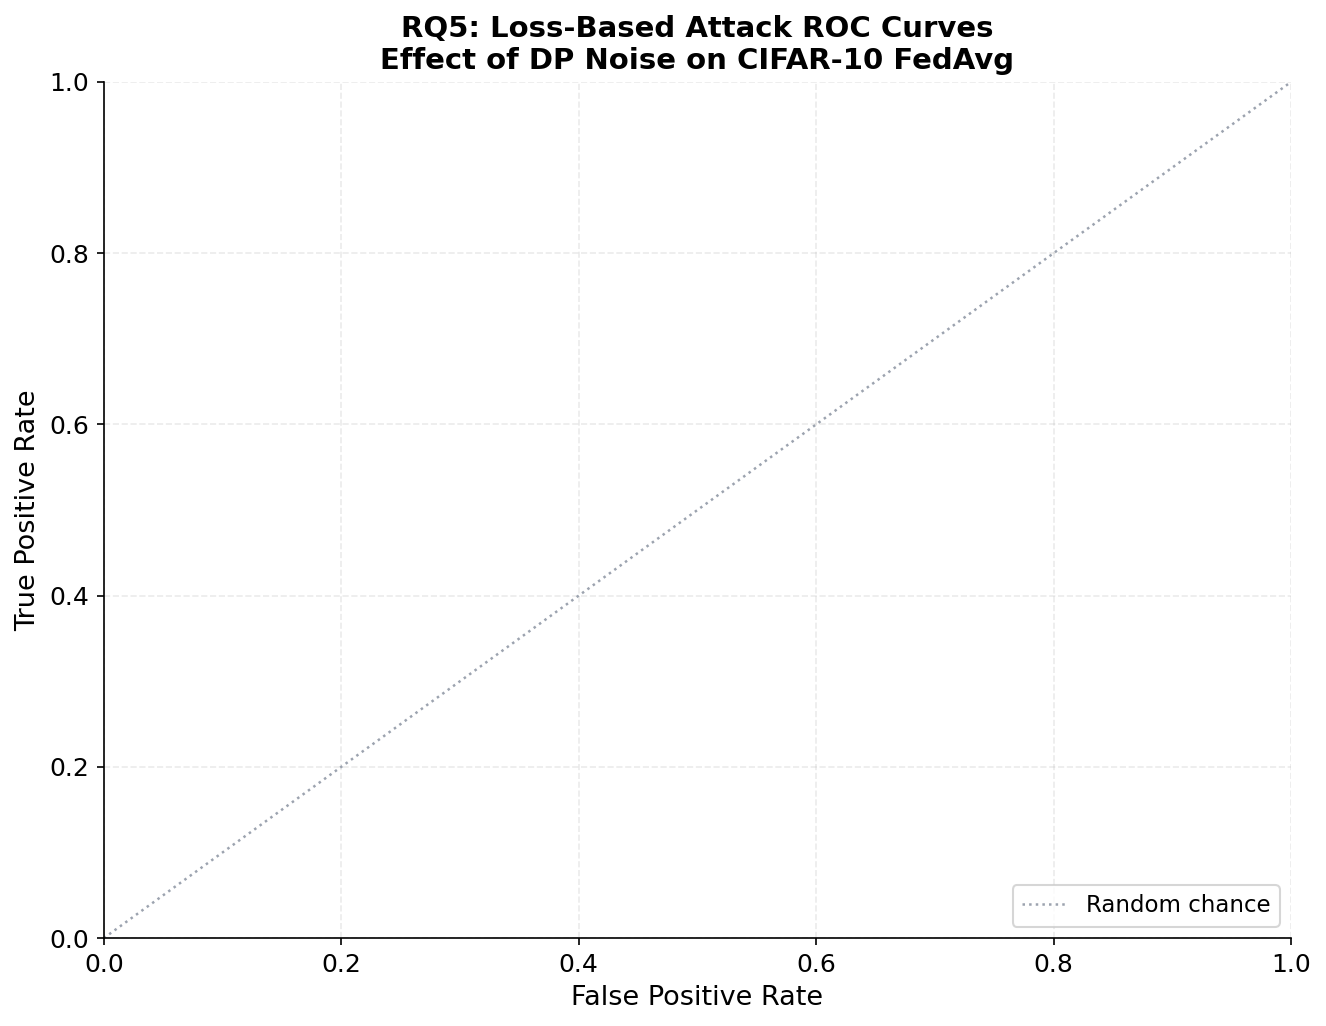

In [12]:
# ── Figure 2: ROC curves ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))

for key, label, color, ls in [
    ('no_dp', f'No DP — AUC = {all_results["no_dp"]["auc_loss"]:.3f}',  NAVY,   '-'),
    ('eps_50', f'ε = 50 — AUC = {all_results["eps_50"]["auc_loss"]:.3f}', GOLD, '--'),
]:
    if key in all_results and 'fpr_loss' in all_results[key]:
        ax.plot(all_results[key]['fpr_loss'], all_results[key]['tpr_loss'],
                color=color, linewidth=2.2, linestyle=ls, label=label)

ax.plot([0,1],[0,1], color='#9CA3AF', linewidth=1.2, linestyle=':', label='Random chance')
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('RQ5: Loss-Based Attack ROC Curves\nEffect of DP Noise on CIFAR-10 FedAvg',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dp_roc_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 12. Figure 3 — Dual-Axis Tradeoff Curve
Line plot showing accuracy (left axis) and attack AUC (right axis) across epsilon.
This directly visualises the privacy-utility tradeoff — the core contribution of this notebook.

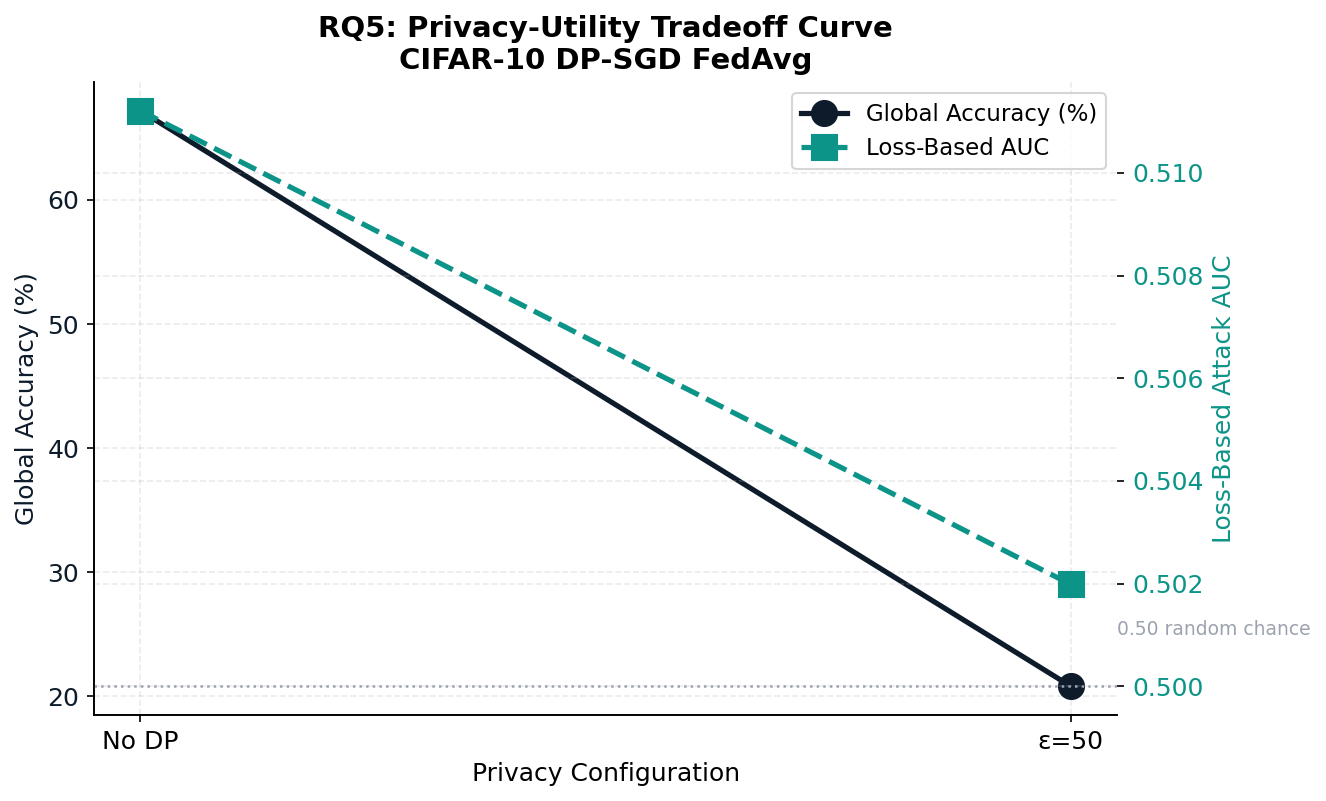

Saved: dp_tradeoff_curve.png


In [13]:
# ── Figure 3: Dual-axis tradeoff line chart ───────────────────────────────────
x_labels = []
acc_vals  = []
auc_vals  = []

for key, r in all_results.items():
    x_labels.append('No DP' if r['epsilon'] is None else f"ε={r['epsilon']}")
    acc_vals.append(r['global_acc'] * 100)
    auc_vals.append(r['auc_loss'])

x = np.arange(len(x_labels))

fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

ax1.plot(x, acc_vals, 'o-', color=NAVY, linewidth=2.5, markersize=12, label='Global Accuracy (%)')
ax2.plot(x, auc_vals, 's--', color=TEAL, linewidth=2.5, markersize=12, label='Loss-Based AUC')

ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, fontsize=12)
ax1.set_ylabel('Global Accuracy (%)', fontsize=12, color=NAVY)
ax2.set_ylabel('Loss-Based Attack AUC', fontsize=12, color=TEAL)
ax1.tick_params(axis='y', labelcolor=NAVY)
ax2.tick_params(axis='y', labelcolor=TEAL)
ax2.axhline(0.50, color='#9CA3AF', linestyle=':', linewidth=1.2)
ax2.text(len(x_labels)-0.95, 0.501, '0.50 random chance', fontsize=9, color='#9CA3AF')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, fontsize=11, loc='upper right')
ax1.set_title('RQ5: Privacy-Utility Tradeoff Curve\nCIFAR-10 DP-SGD FedAvg',
              fontsize=14, fontweight='bold')
ax1.set_xlabel('Privacy Configuration', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dp_tradeoff_curve.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: dp_tradeoff_curve.png')

## 13. Download Results
Downloads the JSON results file and all three figures to your local machine.
Upload the figures to Overleaf and the JSON to the GitHub `results/` folder.

In [15]:
# ── Download all output files ─────────────────────────────────────────────────
from google.colab import files

print('Downloading results...')
files.download(os.path.join(OUTPUT_DIR, 'dp_cifar10_results.json'))
files.download(os.path.join(OUTPUT_DIR, 'dp_privacy_utility_tradeoff.png'))
files.download(os.path.join(OUTPUT_DIR, 'dp_attack_suppression.png'))
files.download(os.path.join(OUTPUT_DIR, 'dp_roc_curves.png'))
files.download(os.path.join(OUTPUT_DIR, 'dp_tradeoff_curve.png'))
print('Done — 5 files downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done — 5 files downloaded
